In [111]:
import numpy as np
from scipy import interpolate
import matplotlib.pyplot as plt

In [112]:
N = 128

np.random.seed(42)
t_k = np.cumsum(np.random.rand(1, N))
t_k -= t_k[0]  # Make it start at 0

fs = N / t_k[-1]
t_eq = np.linspace(t_k[0], t_k[-1], N)

t_k.shape

(128,)

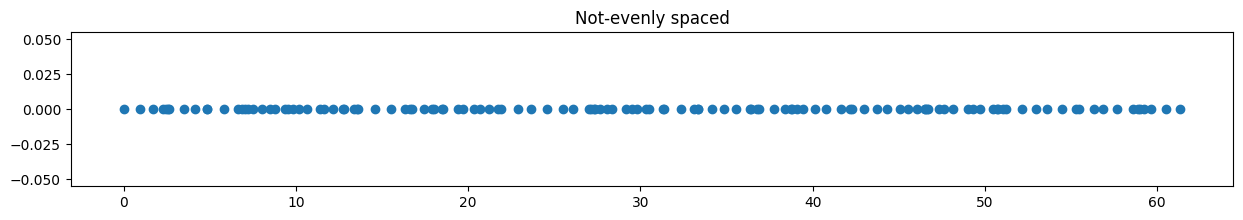

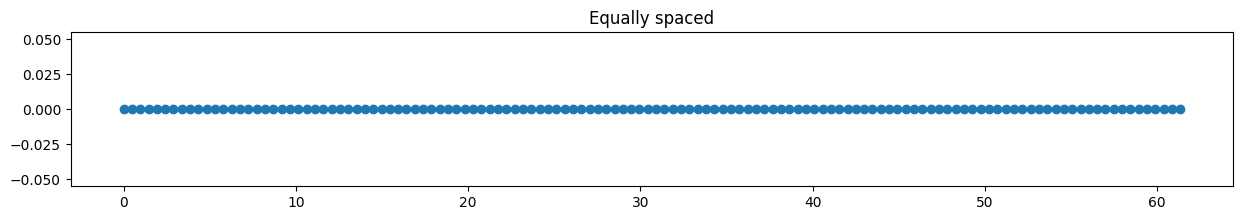

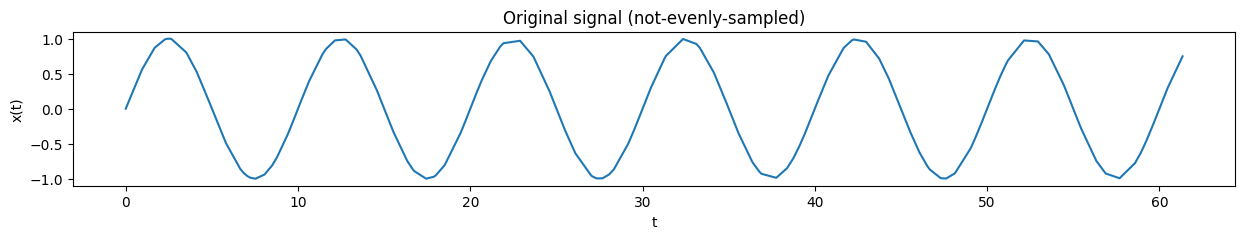

(128,)

In [113]:
f_signal = 0.1
x_nes = np.sin(2 * np.pi * f_signal * t_k)

plt.figure(figsize = (15,2))
plt.scatter(t_k, np.zeros_like(t_k))
plt.title("Not-evenly spaced")
plt.show()

plt.figure(figsize = (15,2))
plt.scatter(t_eq, np.zeros_like(t_k))
plt.title("Equally spaced")
plt.show()

plt.figure(figsize = (15,2))
plt.plot(t_k, x_nes)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Original signal (not-evenly-sampled)")
plt.show()

t_k.shape

In [114]:
# f_vec = np.fft.rfftfreq(N, d=t_k[-1]/N)
f_vec = np.arange(0, fs/2, 0.005)
f_vec.shape, f_vec[1] - f_vec[0], (f_vec[0], f_vec[-1])

((209,), np.float64(0.005), (np.float64(0.0), np.float64(1.04)))

In [115]:
f_vec

array([0.   , 0.005, 0.01 , 0.015, 0.02 , 0.025, 0.03 , 0.035, 0.04 ,
       0.045, 0.05 , 0.055, 0.06 , 0.065, 0.07 , 0.075, 0.08 , 0.085,
       0.09 , 0.095, 0.1  , 0.105, 0.11 , 0.115, 0.12 , 0.125, 0.13 ,
       0.135, 0.14 , 0.145, 0.15 , 0.155, 0.16 , 0.165, 0.17 , 0.175,
       0.18 , 0.185, 0.19 , 0.195, 0.2  , 0.205, 0.21 , 0.215, 0.22 ,
       0.225, 0.23 , 0.235, 0.24 , 0.245, 0.25 , 0.255, 0.26 , 0.265,
       0.27 , 0.275, 0.28 , 0.285, 0.29 , 0.295, 0.3  , 0.305, 0.31 ,
       0.315, 0.32 , 0.325, 0.33 , 0.335, 0.34 , 0.345, 0.35 , 0.355,
       0.36 , 0.365, 0.37 , 0.375, 0.38 , 0.385, 0.39 , 0.395, 0.4  ,
       0.405, 0.41 , 0.415, 0.42 , 0.425, 0.43 , 0.435, 0.44 , 0.445,
       0.45 , 0.455, 0.46 , 0.465, 0.47 , 0.475, 0.48 , 0.485, 0.49 ,
       0.495, 0.5  , 0.505, 0.51 , 0.515, 0.52 , 0.525, 0.53 , 0.535,
       0.54 , 0.545, 0.55 , 0.555, 0.56 , 0.565, 0.57 , 0.575, 0.58 ,
       0.585, 0.59 , 0.595, 0.6  , 0.605, 0.61 , 0.615, 0.62 , 0.625,
       0.63 , 0.635,

In [116]:
def P(t, x, f) -> float:
    return (np.sum(x * np.cos(2 * np.pi * f * t))**2 + np.sum(x * np.sin(2 * np.pi * f * t))**2) / N

def calc_peridogram(t, x) -> np.ndarray:
    per = np.array([P(t, x, f_one) for f_one in f_vec])
    # per *= 2 / len(f_vec)
    return per

In [117]:
def print_dominant_freq(peridogram, per_name):
    f_dom = f_vec[peridogram.argmax()]
    print(f"Dominant frequency: {f_dom} for {per_name} peridogram")

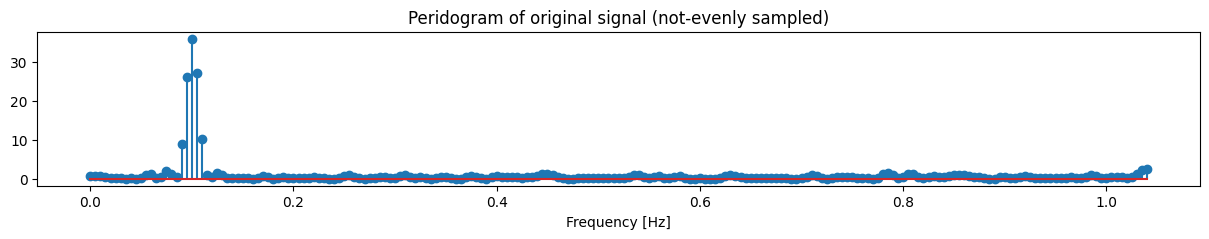

In [118]:
peridogram_original = calc_peridogram(t_k, x_nes)

plt.figure(figsize = (15,2))
plt.title("Peridogram of original signal (not-evenly sampled)")
plt.stem(f_vec, peridogram_original)
plt.xlabel("Frequency [Hz]")
plt.show()

In [119]:
print_dominant_freq(peridogram_original, "original")

Dominant frequency: 0.1 for original peridogram


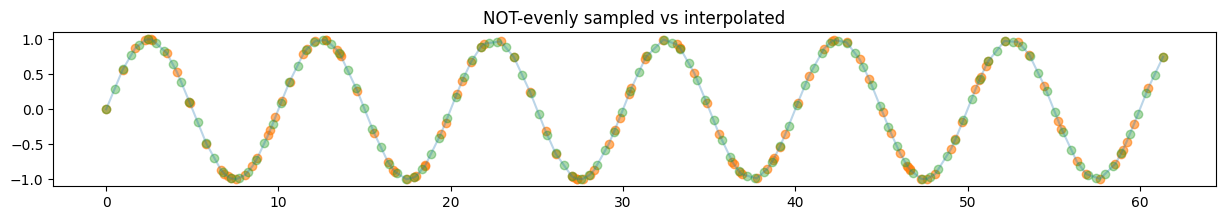

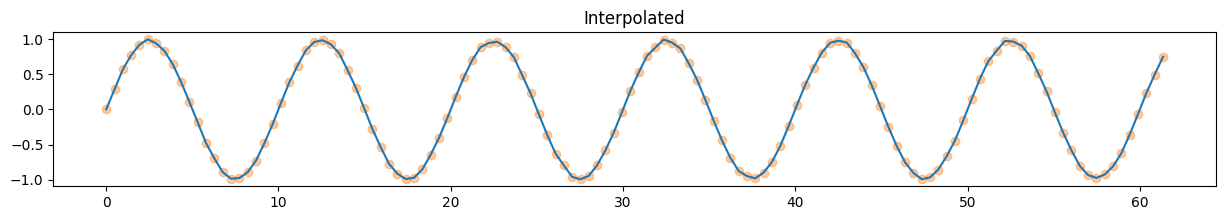

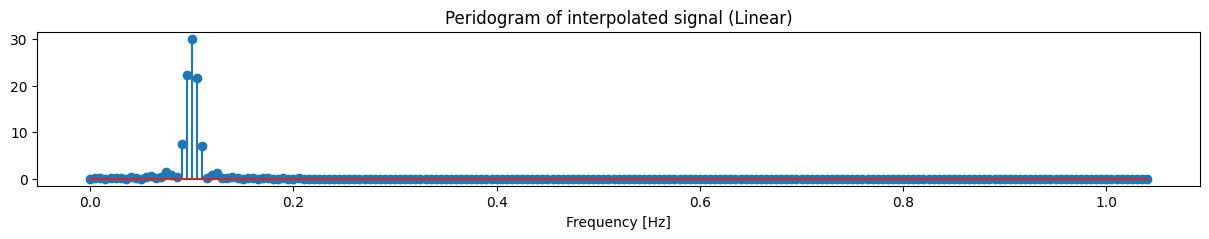

In [120]:
x_lin = np.interp(t_eq, t_k, x_nes)

plt.figure(figsize = (15,2))
plt.plot(t_k, x_nes, alpha=0.3)
plt.scatter(t_k, x_nes, color="tab:orange", alpha=0.6)
plt.scatter(t_eq, x_lin, color="tab:green", alpha=0.4)
plt.title("NOT-evenly sampled vs interpolated")
plt.show()

plt.figure(figsize = (15,2))
plt.plot(t_eq, x_lin)
plt.title("Interpolated")
plt.scatter(t_eq, x_lin, color="tab:orange", alpha=0.4)
plt.show()

peridogram_lin = calc_peridogram(t_eq, x_lin)

plt.figure(figsize = (15,2))
plt.title("Peridogram of interpolated signal (Linear)")
plt.stem(f_vec, peridogram_lin)
plt.xlabel("Frequency [Hz]")
plt.show()

In [121]:
print_dominant_freq(peridogram_lin, "linear-interpolated")

Dominant frequency: 0.1 for linear-interpolated peridogram


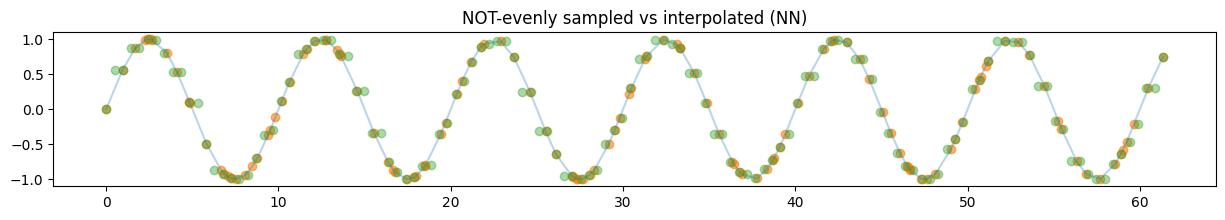

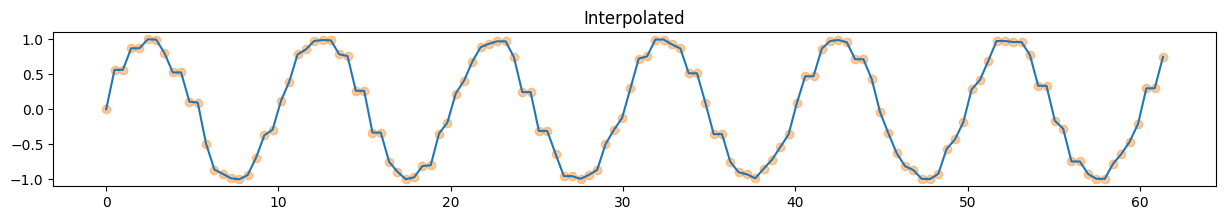

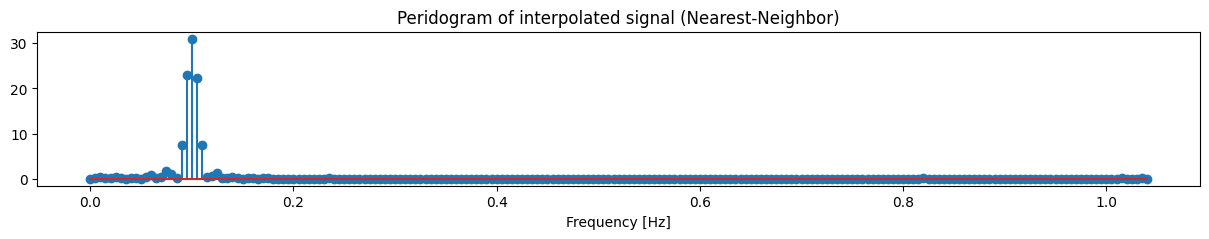

In [122]:
nnInterpolator = interpolate.interp1d(t_k, x_nes, kind="nearest")
x_nn = nnInterpolator(t_eq)

plt.figure(figsize = (15,2))
plt.plot(t_k, x_nes, alpha=0.3)
plt.scatter(t_k, x_nes, color="tab:orange", alpha=0.6)
plt.scatter(t_eq, x_nn, color="tab:green", alpha=0.4)
plt.title("NOT-evenly sampled vs interpolated (NN)")
plt.show()

plt.figure(figsize = (15,2))
plt.plot(t_eq, x_nn)
plt.title("Interpolated")
plt.scatter(t_eq, x_nn, color="tab:orange", alpha=0.4)
plt.show()

peridogram_nn = calc_peridogram(t_eq, x_nn)

plt.figure(figsize = (15,2))
plt.title("Peridogram of interpolated signal (Nearest-Neighbor)")
plt.stem(f_vec, peridogram_nn)
plt.xlabel("Frequency [Hz]")
plt.show()

In [123]:
print_dominant_freq(peridogram_nn, "nn-interpolated")

Dominant frequency: 0.1 for nn-interpolated peridogram


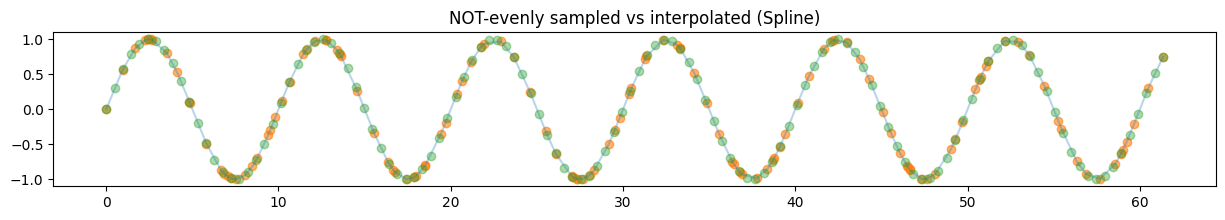

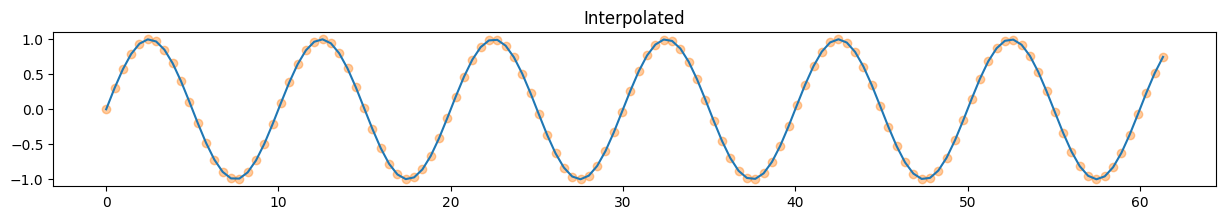

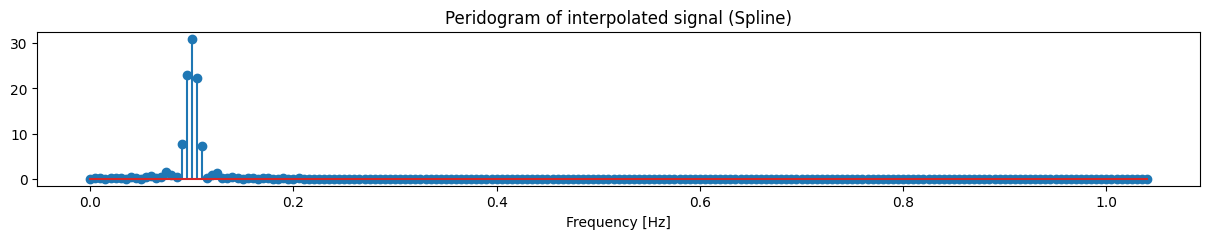

In [124]:
splineInterpolator = interpolate.interp1d(t_k, x_nes, kind="cubic")
x_spline = splineInterpolator(t_eq)

plt.figure(figsize = (15,2))
plt.plot(t_k, x_nes, alpha=0.3)
plt.scatter(t_k, x_nes, color="tab:orange", alpha=0.6)
plt.scatter(t_eq, x_spline, color="tab:green", alpha=0.4)
plt.title("NOT-evenly sampled vs interpolated (Spline)")
plt.show()

plt.figure(figsize = (15,2))
plt.plot(t_eq, x_spline)
plt.title("Interpolated")
plt.scatter(t_eq, x_spline, color="tab:orange", alpha=0.4)
plt.show()

peridogram_spline = calc_peridogram(t_eq, x_spline)

plt.figure(figsize = (15,2))
plt.title("Peridogram of interpolated signal (Spline)")
plt.stem(f_vec, peridogram_spline)
plt.xlabel("Frequency [Hz]")
plt.show()

In [125]:
print_dominant_freq(peridogram_spline, "spline-interpolated")

Dominant frequency: 0.1 for spline-interpolated peridogram


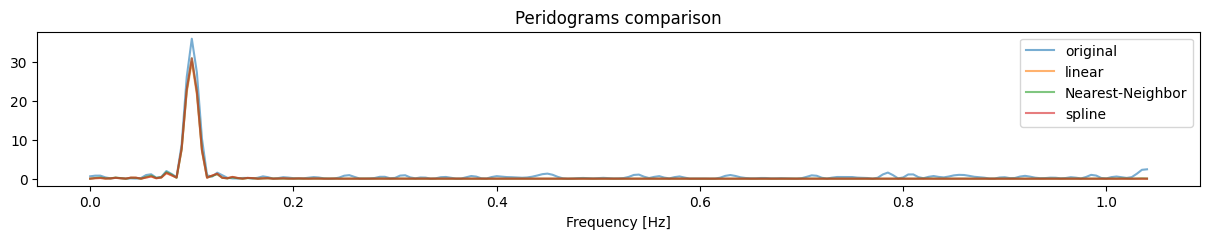

In [126]:
plt.figure(figsize = (15,2))
plt.title("Peridograms comparison")
plt.plot(f_vec, peridogram_original, label="original", alpha=0.6)
plt.plot(f_vec, peridogram_lin, label="linear", alpha=0.6)
plt.plot(f_vec, peridogram_nn, label="Nearest-Neighbor", alpha=0.6)
plt.plot(f_vec, peridogram_spline, label="spline", alpha=0.6)
plt.legend()
plt.xlabel("Frequency [Hz]")
plt.show()

In [127]:
def P_LS(t, x, f) -> float:
    if f == 0:
        return 0.0

    num_tau = np.sum(np.sin(4 * np.pi * f * t))
    den_tau = np.sum(np.cos(4 * np.pi * f * t))
    tau = (1 / (4 * np.pi * f)) * np.arctan2(num_tau, den_tau)

    t_tau = t - tau

    cos_term = np.sum(x * np.cos(2 * np.pi * f * t_tau))
    sin_term = np.sum(x * np.sin(2 * np.pi * f * t_tau))

    sum_cos_sq = np.sum(np.cos(2 * np.pi * f * t_tau) ** 2)
    sum_sin_sq = np.sum(np.sin(2 * np.pi * f * t_tau) ** 2)

    if sum_cos_sq == 0 or sum_sin_sq == 0:
        return 0.0

    pls = 0.5 * ((cos_term ** 2 / sum_cos_sq) + (sin_term ** 2 / sum_sin_sq))
    return pls


def calc_periodogram_ls(t, x) -> np.ndarray:
    return np.array([P_LS(t, x, f_one) for f_one in f_vec])

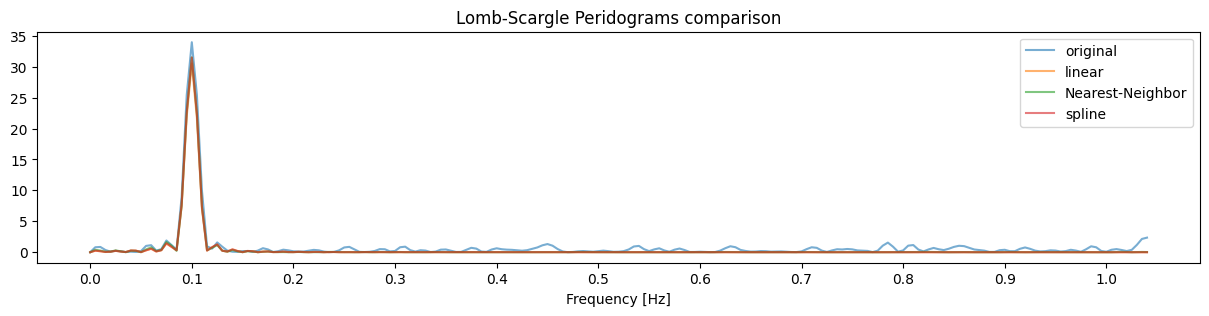

In [128]:
peridogram_original_ls = calc_periodogram_ls(t_k, x_nes)
peridogram_lin_ls = calc_periodogram_ls(t_eq, x_lin)
peridogram_nn_ls = calc_periodogram_ls(t_eq, x_nn)
peridogram_spline_ls = calc_periodogram_ls(t_eq, x_spline)

plt.figure(figsize=(15, 3))
plt.title("Lomb-Scargle Peridograms comparison")
plt.plot(f_vec, peridogram_original_ls, label="original", alpha=0.6)
plt.plot(f_vec, peridogram_lin_ls, label="linear", alpha=0.6)
plt.plot(f_vec, peridogram_nn_ls, label="Nearest-Neighbor", alpha=0.6)
plt.plot(f_vec, peridogram_spline_ls, label="spline", alpha=0.6)
plt.xlabel("Frequency [Hz]")
plt.xticks(np.arange(0, f_vec[-1], 0.1))
plt.legend()
plt.show()

In [129]:
print_dominant_freq(peridogram_original_ls, "Lomb-Scargle (on original signal)")

Dominant frequency: 0.1 for Lomb-Scargle (on original signal) peridogram


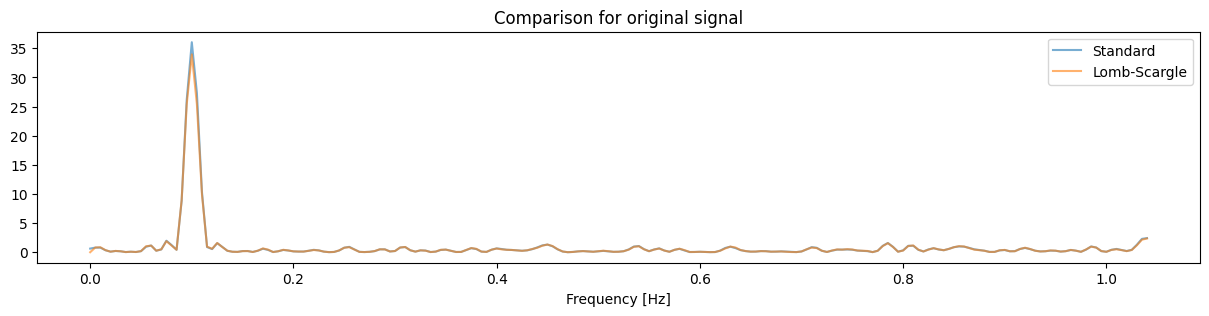

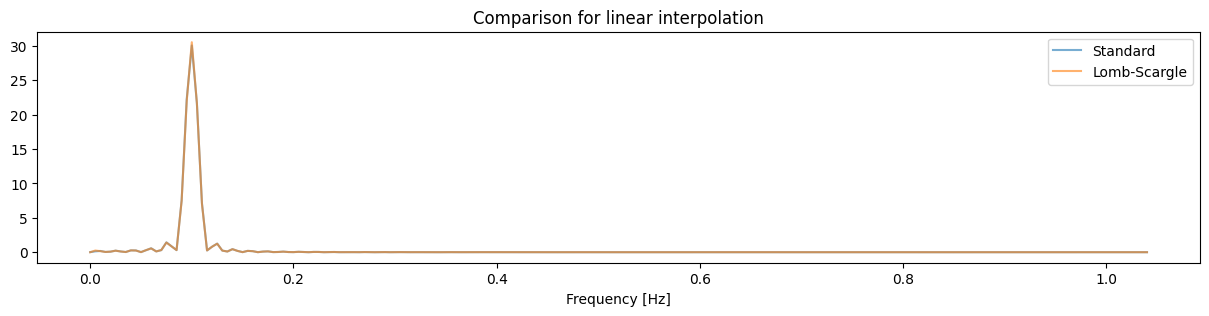

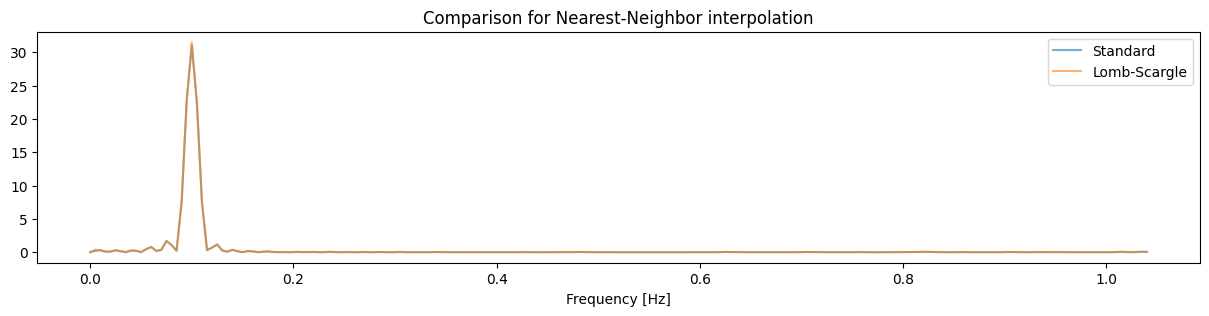

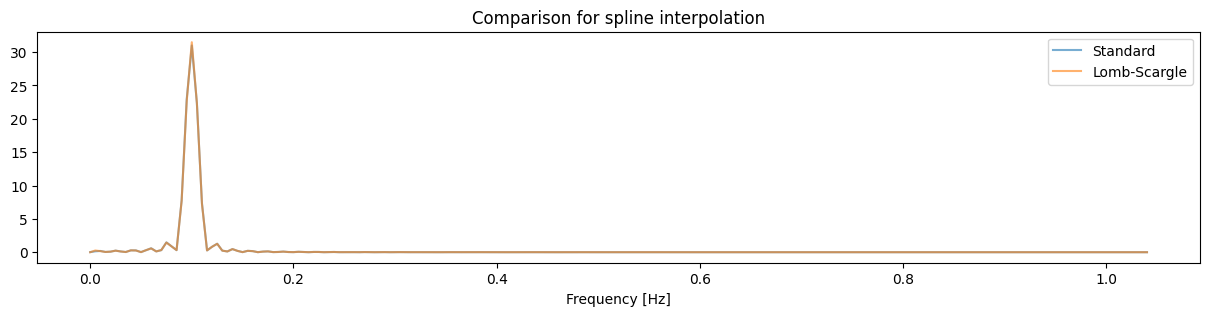

In [130]:
plt.figure(figsize=(15, 3))
plt.title("Comparison for original signal")
plt.plot(f_vec, peridogram_original, label="Standard", alpha=0.6)
plt.plot(f_vec, peridogram_original_ls, label="Lomb-Scargle", alpha=0.6)
plt.xlabel("Frequency [Hz]")
plt.legend()
plt.show()

plt.figure(figsize=(15, 3))
plt.title("Comparison for linear interpolation")
plt.plot(f_vec, peridogram_lin, label="Standard", alpha=0.6)
plt.plot(f_vec, peridogram_lin_ls, label="Lomb-Scargle", alpha=0.6)
plt.xlabel("Frequency [Hz]")
plt.legend()
plt.show()

plt.figure(figsize=(15, 3))
plt.title("Comparison for Nearest-Neighbor interpolation")
plt.plot(f_vec, peridogram_nn, label="Standard", alpha=0.6)
plt.plot(f_vec, peridogram_nn_ls, label="Lomb-Scargle", alpha=0.6)
plt.xlabel("Frequency [Hz]")
plt.legend()
plt.show()

plt.figure(figsize=(15, 3))
plt.title("Comparison for spline interpolation")
plt.plot(f_vec, peridogram_spline, label="Standard", alpha=0.6)
plt.plot(f_vec, peridogram_spline_ls, label="Lomb-Scargle", alpha=0.6)
plt.xlabel("Frequency [Hz]")
plt.legend()
plt.show()